# 47211 – Integrated Danish energy system
**Battery storage · Power-to-X · Waste heat recovery · Biomass-supported PtX**

Notebook based on the latest `47211_project(2).zip` (2025 hourly Energinet data), and the previous `battery_simulation.py`, `ptx_energy_screening.py` and `heat_recovery_simulation.py`. All code needed for the analysis is in this notebook. Place it in the project root (with `data/`), or next to the original ZIP. No external Python scripts or API calls are needed.

## Model scope
- Isolated electricity system; annual renewable production fixed at 580 PJ. Biomass budget of 150 PJ is **assumed electrical output**, not fuel input. The assumed 20 GW biomass power limit is a screening parameter, not a verified Danish plant capacity.
- Short truck trips (<150 km): BEV; long trips: methanol. Light transport is electrified; shipping uses methanol, aviation e-kerosene. Hydrogen is an implicit intermediate product, not a separately sized plant or storage system. No fertilizer/medical demand.
- All dispatch flows are MWh per one-hour interval (numerically equal to mean MW); annual totals are in PJ. Battery capacity is usable energy.
- Dispatch is a rule-based screening model, not an economic optimum. Fuel production has constant efficiencies, no start-up/minimum-load constraints, and no separate CO₂, water or hydrogen subsystem. Heat demand is synthetic; COP is constant. Waste heat is an effective delivered-heat fraction of methanol conversion losses only, with no thermal storage or additional heat-network electricity modeled.


In [1]:
%matplotlib inline
from pathlib import Path
from dataclasses import dataclass
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PJ = 3.6e-6  # PJ per MWh
RENEWABLE_PJ = 580.0
BIOMASS_PJ = 150.0
BIOMASS_GW = 20.0
HOUSEHOLDS_PJ = 300.0
INDUSTRY_PJ = 180.0
TRUCK_SHARE = 0.356
TRUCK_BEV_PJ = 50 * TRUCK_SHARE * 0.4
TRUCK_MEOH_PJ = 50 * (1-TRUCK_SHARE) * 1.1
LIGHT_BEV_PJ = 100 * 0.30
HEAT_PJ = 240.0  # assumed useful heat demand, part of 300 PJ
MEOH_PJ = TRUCK_MEOH_PJ + 50.0
KEROSENE_PJ = 50.0
ETA_MEOH = 0.50
ETA_KEROSENE = 0.40
ETA_CH = ETA_DIS = 0.95
DURATION_H = 4.0
PTX_GW = 20.0
CAPACITIES = [0, 25, 50, 100, 200]
TARGETS = np.array([MEOH_PJ/ETA_MEOH, KEROSENE_PJ/ETA_KEROSENE])/PJ
SHARES = TARGETS / TARGETS.sum()

print(f'Truck electricity: {TRUCK_BEV_PJ:.2f} PJ; truck methanol: {TRUCK_MEOH_PJ:.2f} PJ')
print(f'Full PtX electricity target: {TARGETS.sum()*PJ:.2f} PJ')

Truck electricity: 7.12 PJ; truck methanol: 35.42 PJ
Full PtX electricity target: 295.84 PJ


## 1. Read and validate project data
Use the most recent modified CSV. Re-scale the original wind + solar profile without intermediate rounding, and explicitly add truck electricity to the 480 PJ base profile. The local hours 19 through 06 are the 12 charging-hour labels in your existing notebook (19:00–07:00 as interval boundaries). UTC sorting avoids daylight-saving ordering issues.

In [2]:
filename = 'ProductionConsumptionSettlement_DK_modified.csv'
paths = [Path('data')/filename, Path('47211_project/data')/filename]
source = next((p for p in paths if p.is_file()), None)
if source is not None:
    data = pd.read_csv(source, sep=';', decimal=',')
else:
    archives = [Path('47211_project(2).zip'), Path('47211_project.zip')]
    archive = next((p for p in archives if p.is_file()), None)
    if archive is None:
        raise FileNotFoundError('Place notebook in the project root, or beside 47211_project(2).zip.')
    with zipfile.ZipFile(archive) as z:
        matches = [p for p in z.namelist() if p.endswith('/data/'+filename)]
        if len(matches) != 1:
            raise ValueError(f'Expected one matching CSV, got {matches}')
        with z.open(matches[0]) as f:
            data = pd.read_csv(f, sep=';', decimal=',')
    source = archive

data['HourUTC'] = pd.to_datetime(data.HourUTC)
data['HourDK'] = pd.to_datetime(data.HourDK)
data = data.sort_values('HourUTC').reset_index(drop=True)
N = len(data)
assert N == 8760 and data.HourUTC.is_unique
assert data.HourUTC.diff().dropna().eq(pd.Timedelta(hours=1)).all()

def scaled(a, annual_pj):
    a = np.asarray(a, dtype=float)
    assert np.isfinite(a).all() and (a >= 0).all() and a.sum() > 0
    return a * annual_pj / (PJ*a.sum())

renew = scaled(data.TotalRenewableMWh, RENEWABLE_PJ)
base = scaled(data.GrossConsumptionScaledMWh, HOUSEHOLDS_PJ+INDUSTRY_PJ)
trucks = scaled(data.TrucksElectricityDemandMWh, TRUCK_BEV_PJ)
charging = (data.HourDK.dt.hour >= 19) | (data.HourDK.dt.hour < 7)
assert np.allclose(trucks[~charging], 0)
assert np.allclose(trucks[charging], trucks[charging][0])
light = np.full(N, LIGHT_BEV_PJ/PJ/N)
# Preserve the previous synthetic heat-profile approach: seasonally split the base profile.
season = np.cos(2*np.pi*(data.HourDK.dt.dayofyear.to_numpy()-15)/365)
f = HEAT_PJ/(HOUSEHOLDS_PJ+INDUSTRY_PJ) + .30*(season-np.average(season, weights=base))
assert np.all((f>=0)&(f<=1))
heat = base*f
other = base-heat+trucks+light
assert np.isclose(heat.sum()*PJ, HEAT_PJ)
print('Input:', source, '| hours:', N)
display(pd.Series({'Wind + solar':renew.sum()*PJ,'Base direct demand':base.sum()*PJ,
                   'BEV trucks':trucks.sum()*PJ,'BEV light transport':light.sum()*PJ,
                   'Useful heat (within base)':heat.sum()*PJ}, name='Annual PJ').round(3))


Input: 47211_project(2).zip | hours: 8760


Wind + solar                 580.00
Base direct demand           480.00
BEV trucks                     7.12
BEV light transport           30.00
Useful heat (within base)    240.00
Name: Annual PJ, dtype: float64

## 2. Shared hourly dispatch model
With $E_t$ as usable battery energy, $E_{t+1}=E_t+\eta_{ch}C_t-D_t/\eta_{dis}$ (one-hour intervals). Renewable electricity covers direct demand first; surplus charges the battery, then supplies PtX. Battery discharge covers deficits, followed by biomass. Only in biomass-enabled runs may the remaining biomass power and annual budget feed PtX. No biomass is deliberately used to charge batteries. PtX uses the same fixed input shares for both fuels in each hour, and stops when the annual target is reached. For the truck-only screening a single methanol target is used.

Heat recovery is simultaneous: $Q_{used}=\min(Q_{demand}, f_{WH}(1-\eta_{MeOH})E_{PtM,el})$ and $E_{direct}=E_{other}+(Q_{demand}-Q_{used})/COP$. Solve this hourly by fixed-point iteration. In this abstraction, biomass-generated electricity may also create PtX heat.

A conservative reserve protects direct demand: first run a no-recovery, no-PtX battery dispatch with the same COP and capacity. Reserve its biomass use for direct loads; the rest of the 150 PJ budget is available to PtX. This may leave unused biomass if the reserve proves larger than needed. One shared hourly 20 GW cap and one shared annual 150 PJ cap always apply. No guaranteed feasibility if parameters are changed. Annual battery SOC is cyclic by repeating the same year until start/end SOC match.

In [3]:
@dataclass(frozen=True)
class Scenario:
    name: str
    battery_gwh: float
    cop: float = 1.0
    recovery: float = 0.0
    ptx_gw: float = 0.0
    bio_ptx_gw: float = 0.0  # additional cap specifically for biomass to PtX
    include_light: bool = True
    target_pj: tuple = (MEOH_PJ/ETA_MEOH, KEROSENE_PJ/ETA_KEROSENE)
    eta_meoh: float = ETA_MEOH
    eta_kerosene: float = ETA_KEROSENE

COLS = ['direct','heat_used','heat_available','charge','discharge','soc','bio_direct',
        'bio_ptx','ptx_renew','ptm','ptk','spill','unmet','battery_loss']

def simulate_once(s, initial, bio_ptx_budget):
    cap = s.battery_gwh*1000
    power = cap/DURATION_H
    target = np.asarray(s.target_pj)/PJ
    remaining_target = target.sum()
    share_m = target[0]/remaining_target if remaining_target else 0.0
    biomass_left = BIOMASS_PJ/PJ
    ptx_bio_left = bio_ptx_budget
    soc = initial
    out = np.empty((N,len(COLS)))
    oprofile = other if s.include_light else other-light
    for i, (r,o,h) in enumerate(zip(renew,oprofile,heat)):
        def flows(q):
            demand = o+(h-q)/s.cop
            net = r-demand
            ch = min(max(net,0.),power,max(cap-soc,0.)/ETA_CH)
            dis = min(max(-net,0.),power,max(soc,0.)*ETA_DIS)
            deficit = max(-net-dis,0.)
            bd = min(deficit, BIOMASS_GW*1000, biomass_left)
            unmet = max(deficit-bd,0.)
            surplus = max(net-ch,0.)
            pr = min(surplus,s.ptx_gw*1000,remaining_target)
            bp = 0.
            if unmet < 1e-8:
                bp = min(max(s.ptx_gw*1000-pr,0.),max(remaining_target-pr,0.),
                         s.bio_ptx_gw*1000,max(BIOMASS_GW*1000-bd,0.),
                         max(biomass_left-bd,0.),ptx_bio_left)
            pm = (pr+bp)*share_m
            pk = (pr+bp)*(1-share_m)
            q_available = s.recovery*(1-s.eta_meoh)*pm
            return demand,ch,dis,bd,bp,pr,pm,pk,surplus-pr,unmet,q_available
        q=0.
        for _ in range(60):
            vals = flows(q)
            new = min(h,vals[-1])
            if abs(new-q)<1e-8:
                break
            q=new
        else:
            raise RuntimeError('Hourly heat fixed point did not converge')
        demand,ch,dis,bd,bp,pr,pm,pk,spill,unmet,q_available=vals
        soc += ETA_CH*ch-dis/ETA_DIS
        biomass_left=max(0.,biomass_left-bd-bp)
        ptx_bio_left=max(0.,ptx_bio_left-bp)
        remaining_target=max(0.,remaining_target-pr-bp)
        loss=ch*(1-ETA_CH)+dis*(1/ETA_DIS-1)
        out[i]=demand,q,q_available,ch,dis,soc,bd,bp,pr,pm,pk,spill,unmet,loss
    a=pd.DataFrame(out,columns=COLS)
    return a

def cyclic(s, bio_ptx_budget=0.):
    initial=0.
    for _ in range(100):
        a=simulate_once(s,initial,bio_ptx_budget)
        end=a.soc.iloc[-1]
        if abs(end-initial)<1e-5:
            break
        initial=end
    else:
        raise RuntimeError('Cyclic SOC did not converge')
    # Hourly electricity balance, battery balance, heat balance and annual constraints
    err=renew+a.bio_direct+a.bio_ptx+a.discharge+a.unmet-a.direct-a.charge-a.ptm-a.ptk-a.spill
    assert np.max(np.abs(err)) < 1e-5
    assert np.allclose(np.diff(np.r_[initial,a.soc]),ETA_CH*a.charge-a.discharge/ETA_DIS,atol=1e-6)
    assert a.soc.min() >= -1e-6 and a.soc.max() <= s.battery_gwh*1000+1e-6
    assert np.allclose(a.direct,(other if s.include_light else other-light)+(heat-a.heat_used)/s.cop,atol=1e-6)
    assert (a.heat_used <= heat+1e-6).all() and (a.heat_used <= a.heat_available+1e-6).all()
    assert (a.bio_direct+a.bio_ptx).max() <= BIOMASS_GW*1000+1e-6
    assert (a.bio_direct+a.bio_ptx).sum()*PJ <= BIOMASS_PJ+1e-6
    assert a.bio_ptx.sum() <= bio_ptx_budget+1e-5
    assert (a.ptm+a.ptk).max() <= s.ptx_gw*1000+1e-6
    assert abs(RENEWABLE_PJ+(a.bio_direct+a.bio_ptx+a.unmet-a.direct-a.ptm-a.ptk-a.spill-a.battery_loss).sum()*PJ)<1e-5
    return a

from dataclasses import replace

def run(s):
    if s.bio_ptx_gw>0:
        reference=replace(s,recovery=0,ptx_gw=0,bio_ptx_gw=0)
        reserve=cyclic(reference).bio_direct.sum()
        quota=max(0,BIOMASS_PJ/PJ-reserve)
    else:
        reserve=quota=0.
    a=cyclic(s,quota)
    if s.bio_ptx_gw>0:
        assert a.bio_direct.sum() <= reserve+1e-4, 'Direct reserve exceeded; revise dispatch'
    return a

def summarize(s,a):
    annual=a.sum()*PJ
    target=sum(s.target_pj)
    used=annual.ptm+annual.ptk
    return dict(scenario=s.name,BESS_GWh=s.battery_gwh,BESS_GW=s.battery_gwh/DURATION_H,
                COP=s.cop,heat_recovery=s.recovery,PtX_GW=s.ptx_gw,bio_PtX_cap_GW=s.bio_ptx_gw,
                direct_PJ=annual.direct,heat_used_PJ=annual.heat_used,
                biomass_direct_PJ=annual.bio_direct,biomass_PtX_PJ=annual.bio_ptx,
                biomass_total_PJ=annual.bio_direct+annual.bio_ptx,
                PtX_renewable_PJ=annual.ptx_renew,PtX_input_PJ=used,
                methanol_PJ=annual.ptm*s.eta_meoh,kerosene_PJ=annual.ptk*s.eta_kerosene,
                PtX_coverage_pct=100*used/target if target else np.nan,
                curtailment_PJ=annual.spill,battery_loss_PJ=annual.battery_loss,
                unmet_direct_PJ=annual.unmet,unmet_PtX_PJ=max(0,target-used),
                max_charge_GW=a.charge.max()/1000,max_discharge_GW=a.discharge.max()/1000,
                max_biomass_GW=(a.bio_direct+a.bio_ptx).max()/1000)


## 3. Battery-only sensitivity (original truck-inclusive baseline)
Here light transport is excluded to reproduce the first battery study. With PtX disabled, the reported curtailment represents electricity available to a hypothetical flexible PtX load. The 4 h battery rating and 95% efficiencies are unchanged.

,BESS_GWh,BESS_GW,biomass_total_PJ,curtailment_PJ,battery_loss_PJ,unmet_direct_PJ,max_charge_GW,max_discharge_GW
0,0,0.00,89.266,182.146,0.000,0.0,0.00,0.000
1,25,6.25,76.721,168.246,1.355,0.0,6.25,6.250
2,50,12.50,69.289,160.011,2.158,0.0,12.50,12.500
3,100,25.00,58.314,147.851,3.344,0.0,25.00,16.424
4,200,50.00,44.978,133.073,4.785,0.0,29.68,16.962


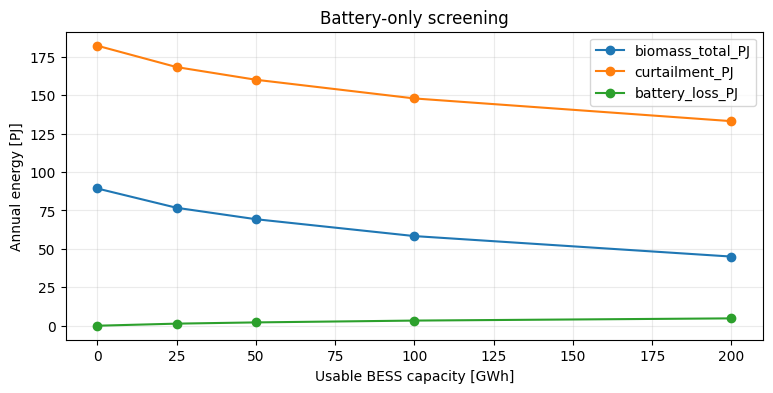

In [4]:
battery_rows=[]; battery_profiles={}
for cap in CAPACITIES:
    s=Scenario(f'{cap} GWh',cap,include_light=False,target_pj=(0,0))
    a=run(s); battery_profiles[cap]=a
    battery_rows.append(summarize(s,a))
battery=pd.DataFrame(battery_rows)
display(battery[['BESS_GWh','BESS_GW','biomass_total_PJ','curtailment_PJ','battery_loss_PJ','unmet_direct_PJ','max_charge_GW','max_discharge_GW']].round(3))
ax=battery.plot(x='BESS_GWh',y=['biomass_total_PJ','curtailment_PJ','battery_loss_PJ'],marker='o',figsize=(9,4))
ax.set(xlabel='Usable BESS capacity [GWh]',ylabel='Annual energy [PJ]',title='Battery-only screening'); ax.grid(alpha=.25); plt.show()

## 4. PtX screening for long-distance trucks only
The minimum installed electric power is the smallest rating for which the integral of `min(hourly_surplus, rating)` reaches the annual electricity target. No biomass supplies PtX in this section. This reproduces the earlier truck-only sensitivity and tests 40%, 50%, 55% power-to-methanol efficiencies.

PtX_GW,2,4,6,8,10
BESS_GWh,,,,,
0,48.51,91.28,127.93,158.46,183.47
25,41.45,79.20,112.64,141.31,165.25
50,37.88,72.83,104.23,131.61,154.75
100,33.78,65.25,93.74,118.93,140.61
200,30.25,58.55,84.25,107.00,126.54


BESS_GWh
0      4.445
25     5.211
50     5.716
100    6.472
200    7.355
Name: minimum_PtX_GW, dtype: float64

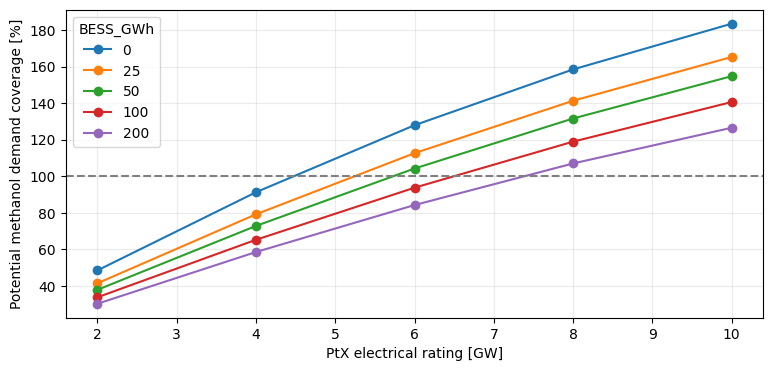

In [5]:
def minimum_power(surplus,target_mwh):
    if surplus.sum()+1e-7<target_mwh:
        return np.nan
    lo,hi=0.,float(surplus.max())
    for _ in range(55):
        mid=(lo+hi)/2
        if np.minimum(surplus,mid).sum()>=target_mwh: hi=mid
        else: lo=mid
    return hi/1000

rows=[]
for cap,a in battery_profiles.items():
    surplus=a.spill.to_numpy()
    for eta in (.4,.5,.55):
        target=TRUCK_MEOH_PJ/eta
        pmin=minimum_power(surplus,target/PJ)
        for power in (2,4,6,8,10):
            potential=np.minimum(surplus,power*1000).sum()*PJ
            rows.append(dict(BESS_GWh=cap,eta=eta,PtX_GW=power,minimum_PtX_GW=pmin,
                             potential_coverage_pct=100*potential/target,
                             allocated_PJ=min(target,potential)))
ptx=pd.DataFrame(rows)
ref=ptx[ptx.eta==.5]
display(ref.pivot(index='BESS_GWh',columns='PtX_GW',values='potential_coverage_pct').round(2))
display(ref.groupby('BESS_GWh').minimum_PtX_GW.first().round(3))
ax=ref.pivot(index='PtX_GW',columns='BESS_GWh',values='potential_coverage_pct').plot(marker='o',figsize=(9,4))
ax.axhline(100,ls='--',color='gray'); ax.set(ylabel='Potential methanol demand coverage [%]',xlabel='PtX electrical rating [GW]'); ax.grid(alpha=.25); plt.show()

## 5. All transport + waste heat recovery
Add the 30 PJ light-transport electricity demand, methanol for trucks and shipping, and e-kerosene for aviation. Compare 12 combinations: battery capacity 25/100 GWh, COP 1/3 and effective delivered heat recovery 0/30/50%. PtX rating = 20 GW; renewable surplus only. No credit for heat from kerosene or biomass generation itself.

,BESS_GWh,COP,heat_recovery,heat_used_PJ,direct_PJ,biomass_total_PJ,PtX_coverage_pct,unmet_direct_PJ
0,25,1,0.0,0.000,517.120,89.664,49.755,0.0
1,25,1,0.3,13.662,503.458,89.664,53.314,0.0
2,25,1,0.5,23.717,493.403,89.664,55.749,0.0
3,25,3,0.0,0.000,357.120,31.765,77.720,0.0
4,25,3,0.3,20.277,350.361,31.765,79.126,0.0
5,25,3,0.5,34.105,345.752,31.765,80.072,0.0
6,100,1,0.0,0.000,517.120,71.030,42.816,0.0
7,100,1,0.3,11.729,505.391,71.030,45.771,0.0
8,100,1,0.5,20.306,496.814,71.030,47.759,0.0
9,100,3,0.0,0.000,357.120,16.056,71.904,0.0


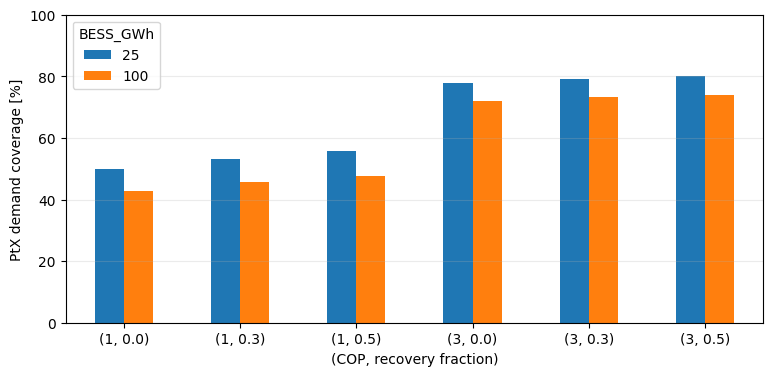

In [6]:
heat_rows=[]
for cap in (25,100):
    for cop in (1,3):
        for rec in (0,.3,.5):
            s=Scenario(f'{cap} GWh, COP {cop}, WH {rec:.0%}',cap,cop,rec,PTX_GW)
            heat_rows.append(summarize(s,run(s)))
heat_results=pd.DataFrame(heat_rows)
display(heat_results[['BESS_GWh','COP','heat_recovery','heat_used_PJ','direct_PJ','biomass_total_PJ','PtX_coverage_pct','unmet_direct_PJ']].round(3))
ax=heat_results.pivot(index=['COP','heat_recovery'],columns='BESS_GWh',values='PtX_coverage_pct').plot.bar(figsize=(9,4),rot=0)
ax.set(ylabel='PtX demand coverage [%]',xlabel='(COP, recovery fraction)',ylim=(0,100)); ax.grid(axis='y',alpha=.25); plt.show()

## 6. Scenario D: biomass supplies PtX
Compare A–D under a consistent set of transport assumptions. A and B use direct electric heating; C uses heat pumps; D adds waste heat and biomass-supported PtX. Include an intermediate D0 (same as D, without biomass to PtX) to isolate the benefit of biomass. We use 20 GW aggregate PtX capacity initially. Vary only the additional biomass-to-PtX power limit, protecting direct loads first. This is a dispatch-policy sensitivity, not a globally optimal capacity sizing. The conservative reserve is recalculated for each battery size and COP.

In [7]:
scenarios=[Scenario('A: large BESS',100,1,0,PTX_GW),
           Scenario('B: small BESS',25,1,0,PTX_GW),
           Scenario('C: heat pumps',25,3,0,PTX_GW),
           Scenario('D0: heat recovery',25,3,.3,PTX_GW),
           Scenario('D: biomass to PtX',25,3,.3,PTX_GW,BIOMASS_GW)]
profiles={}; summaries=[]
for s in scenarios:
    a=run(s); profiles[s.name]=a; summaries.append(summarize(s,a))
comparison=pd.DataFrame(summaries)
key=['scenario','BESS_GWh','direct_PJ','heat_used_PJ','biomass_direct_PJ','biomass_PtX_PJ','biomass_total_PJ','PtX_input_PJ','PtX_coverage_pct','unmet_direct_PJ','unmet_PtX_PJ','curtailment_PJ','battery_loss_PJ']
with pd.option_context("display.max_columns", None):
    display(comparison[key].round(3))


,scenario,BESS_GWh,direct_PJ,heat_used_PJ,biomass_direct_PJ,biomass_PtX_PJ,biomass_total_PJ,PtX_input_PJ,PtX_coverage_pct,unmet_direct_PJ,unmet_PtX_PJ,curtailment_PJ,battery_loss_PJ
0,A: large BESS,100,517.120,0.000,71.030,0.000,71.030,126.668,42.816,0.0,169.172,3.854,3.388
1,B: small BESS,25,517.120,0.000,89.664,0.000,89.664,147.195,49.755,0.0,148.645,3.974,1.375
2,C: heat pumps,25,357.120,0.000,31.765,0.000,31.765,229.926,77.720,0.0,65.914,23.435,1.284
3,D0: heat recovery,25,350.361,20.277,31.765,0.000,31.765,234.085,79.126,0.0,61.755,26.035,1.284
4,D: biomass to PtX,25,348.578,25.626,30.271,118.235,148.506,295.840,100.000,0.0,0.000,82.822,1.266


### 6.1 Power sensitivity and selected Scenario D configuration
Test 10, 15, 20, and 25 GW aggregate PtX ratings with 0–10 GW dedicated biomass-to-PtX caps. In the 20 GW case, also test intermediate caps. Feasibility means zero unmet direct electricity and both annual fuel targets reached; a finite fuel tank and year-to-year reliability are not enforced. Select a feasible 20 GW case with the smallest **tested** biomass support cap (not an exact minimum), or report the highest-coverage case if none succeeds. The cap is a control limit, not a separate biomass plant.

PtX_GW,10,15,20,25
bio_PtX_cap_GW,,,,
0,52.87,68.96,79.13,85.16
1,NaN,NaN,88.32,NaN
2,66.02,84.90,97.31,100.00
3,NaN,NaN,100.00,NaN
4,77.93,99.74,100.00,100.00
5,NaN,NaN,100.00,NaN
6,88.69,100.00,100.00,100.00
8,NaN,NaN,100.00,NaN
10,93.39,100.00,100.00,100.00


,0
scenario,D selected
BESS_GWh,25
direct_PJ,348.578
heat_used_PJ,25.626
biomass_direct_PJ,31.072
biomass_PtX_PJ,74.792
biomass_total_PJ,105.864
PtX_input_PJ,295.84
PtX_coverage_pct,100.0
unmet_direct_PJ,0.0


Annual direct electricity and fuel targets met: True


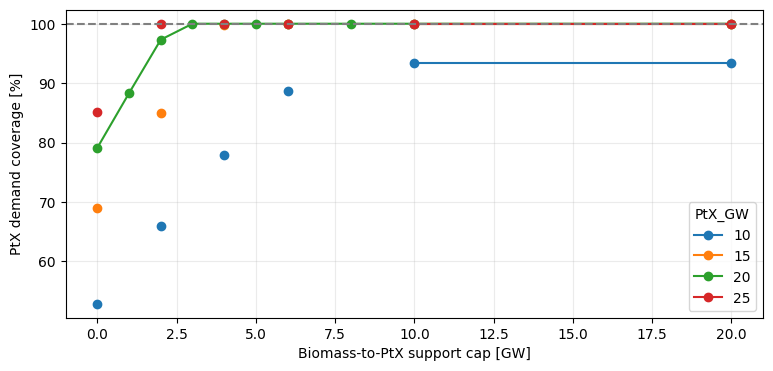

In [8]:
sweep_rows=[]
for p in (10,15,20,25):
    caps=(0,1,2,3,4,5,6,8,10,20) if p==20 else (0,2,4,6,10,20)
    for bp in caps:
        s=Scenario('D sensitivity',25,3,.3,p,bp)
        sweep_rows.append(summarize(s,run(s)))
sweep=pd.DataFrame(sweep_rows)
sweep['feasible']=(sweep.unmet_direct_PJ<1e-6)&(sweep.unmet_PtX_PJ<1e-6)
display(sweep.pivot(index='bio_PtX_cap_GW',columns='PtX_GW',values='PtX_coverage_pct').round(2))
candidates=sweep[(sweep.PtX_GW==PTX_GW)&sweep.feasible].sort_values('bio_PtX_cap_GW')
if len(candidates):
    choice=candidates.iloc[0]
else:
    choice=sweep[sweep.PtX_GW==PTX_GW].sort_values(['PtX_coverage_pct','biomass_total_PJ'],ascending=[False,True]).iloc[0]
selected=Scenario('D selected',25,3,.3,float(choice.PtX_GW),float(choice.bio_PtX_cap_GW))
d=run(selected)
selected_summary=pd.DataFrame([summarize(selected,d)])
display(selected_summary[key+['PtX_GW','bio_PtX_cap_GW','methanol_PJ','kerosene_PJ']].round(3).T)
print('Annual direct electricity and fuel targets met:', bool(choice.feasible))
ax=sweep.pivot(index='bio_PtX_cap_GW',columns='PtX_GW',values='PtX_coverage_pct').plot(marker='o',figsize=(9,4))
ax.axhline(100,color='gray',ls='--'); ax.set(xlabel='Biomass-to-PtX support cap [GW]',ylabel='PtX demand coverage [%]'); ax.grid(alpha=.25); plt.show()

### 6.2 Fuel inventory and final checks
Fuel demand is assumed constant over the year. If annual production meets demand, the minimum working fuel inventory for this fixed production schedule is the range of cumulative production minus demand, with an appropriate initial stock and cyclic year-end stock. This is an ideal storage calculation (no storage losses, reserve requirements, or transport constraints). The electricity simulation alone does not demonstrate physical fuel supply in every hour.

In [9]:
fuel_rows=[]
for label,production,target in [('Methanol',d.ptm.to_numpy()*selected.eta_meoh,MEOH_PJ),('Kerosene',d.ptk.to_numpy()*selected.eta_kerosene,KEROSENE_PJ)]:
    cumulative=np.r_[0,np.cumsum(production-target/PJ/N)]
    cyclic_ok=abs(cumulative[-1])*PJ<1e-6
    fuel_rows.append(dict(fuel=label,production_PJ=production.sum()*PJ,demand_PJ=target,
                          cyclic_feasible=cyclic_ok,
                          working_storage_PJ=np.ptp(cumulative)*PJ if cyclic_ok else np.nan,
                          initial_inventory_PJ=-cumulative.min()*PJ if cyclic_ok else np.nan))
fuel_storage=pd.DataFrame(fuel_rows)
display(fuel_storage.round(4))
# Annual electricity balance (unmet is an accounting slack, not physical production)
s=selected_summary.iloc[0]
balance=pd.Series({'Wind + solar':RENEWABLE_PJ,'Biomass':s.biomass_total_PJ,
                   'Unmet direct (slack)':s.unmet_direct_PJ,'Direct demand':-s.direct_PJ,
                   'PtX electricity':-s.PtX_input_PJ,'Battery losses':-s.battery_loss_PJ,
                   'Curtailment':-s.curtailment_PJ})
display(balance.rename('PJ').round(4)); print('Electricity balance residual [PJ]:',balance.sum())
assert abs(balance.sum())<1e-5
assert s.biomass_total_PJ<=BIOMASS_PJ+1e-6
print('All hourly electricity, heat, SOC and biomass checks passed.')

,fuel,production_PJ,demand_PJ,cyclic_feasible,working_storage_PJ,initial_inventory_PJ
0,Methanol,85.42,85.42,True,4.4496,0.4107
1,Kerosene,50.00,50.00,True,2.6045,0.2404


Wind + solar            580.0000
Biomass                 105.8642
Unmet direct (slack)      0.0000
Direct demand          -348.5780
PtX electricity        -295.8400
Battery losses           -1.2738
Curtailment             -40.1724
Name: PJ, dtype: float64

Electricity balance residual [PJ]: 5.6061821851471905e-12
All hourly electricity, heat, SOC and biomass checks passed.


## 7. Scenario D plots
Weekly averages show seasonal patterns; the example week illustrates actual hourly dispatch, not weekly aggregates. Fuel storage values and the sizing results refer to this modeled year only.

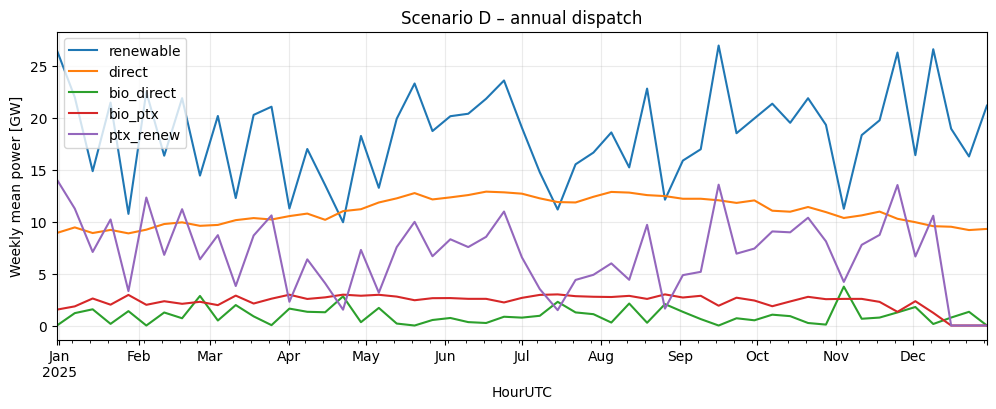

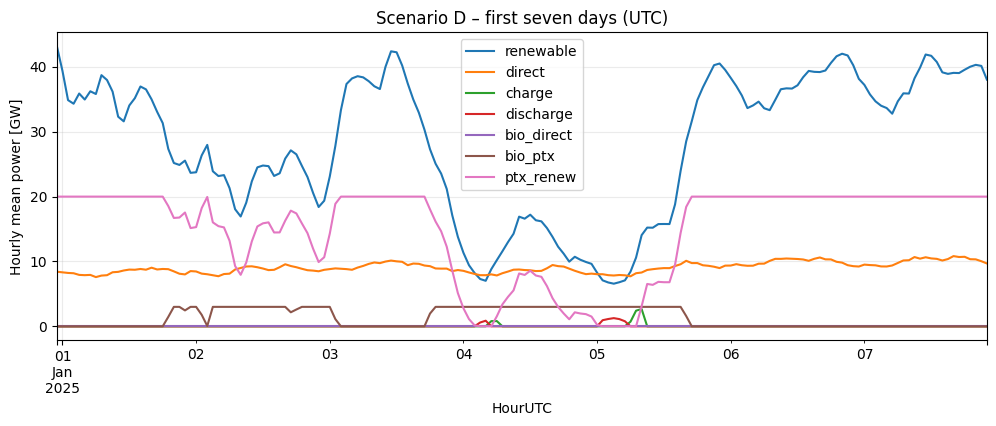

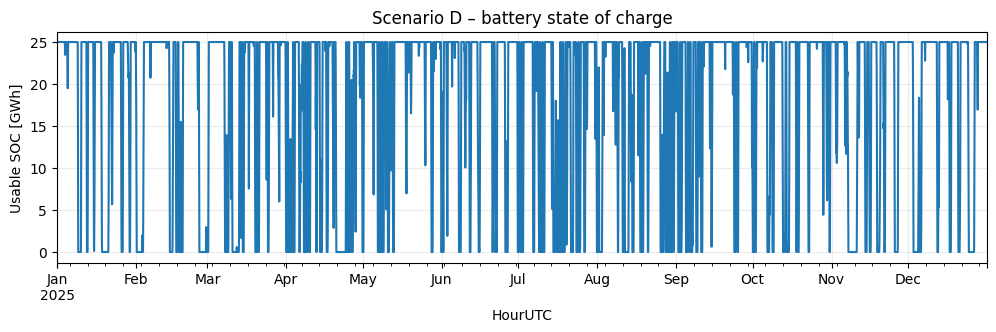

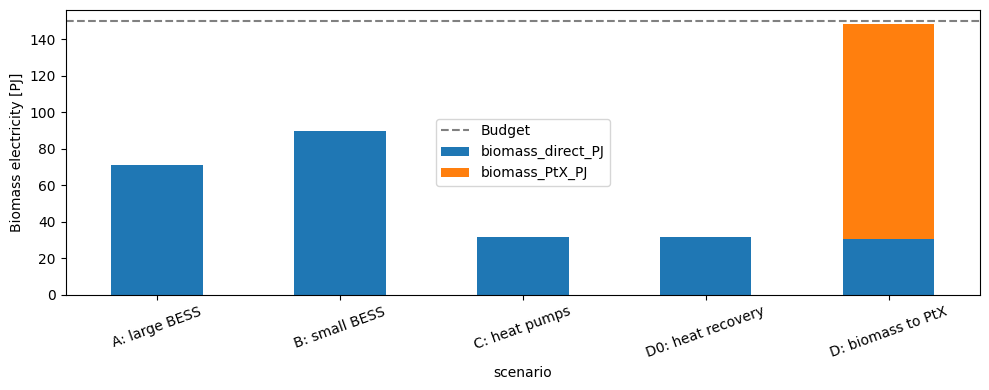

In [10]:
hourly=pd.concat([data[['HourUTC','HourDK']],pd.DataFrame({'renewable':renew,'heat_demand':heat}),d],axis=1).set_index('HourUTC')
weekly=hourly.select_dtypes(include='number').resample('7D').mean()/1000
ax=weekly[['renewable','direct','bio_direct','bio_ptx','ptx_renew']].plot(figsize=(12,4))
ax.set(ylabel='Weekly mean power [GW]',title='Scenario D – annual dispatch'); ax.grid(alpha=.25); plt.show()
week=hourly.iloc[:168]
ax=(week[['renewable','direct','charge','discharge','bio_direct','bio_ptx','ptx_renew']]/1000).plot(figsize=(12,4))
ax.set(ylabel='Hourly mean power [GW]',title='Scenario D – first seven days (UTC)'); ax.grid(alpha=.25); plt.show()
ax=(hourly.soc/1000).plot(figsize=(12,3)); ax.set(ylabel='Usable SOC [GWh]',title='Scenario D – battery state of charge'); ax.grid(alpha=.25); plt.show()
ax=comparison.set_index('scenario')[['biomass_direct_PJ','biomass_PtX_PJ']].plot.bar(stacked=True,figsize=(10,4),rot=20)
ax.axhline(BIOMASS_PJ,color='gray',ls='--',label='Budget'); ax.set(ylabel='Biomass electricity [PJ]'); ax.legend(); plt.tight_layout(); plt.show()

## 8. Export results
Change `EXPORT` to `True` to save summary tables and the full Scenario D hourly time series in a separate folder. Original project files are not changed.

In [ ]:
EXPORT=False
if EXPORT:
    out=Path('data/integrated_results'); out.mkdir(parents=True,exist_ok=True)
    for name,frame in [('battery_scenarios',battery),('ptx_scenarios',ptx),('heat_recovery_scenarios',heat_results),('scenario_comparison',comparison),('scenario_D_sensitivity',sweep),('scenario_D_selected',selected_summary),('scenario_D_fuel_storage',fuel_storage)]:
        frame.to_csv(out/f'{name}.csv',index=False)
    hourly.to_csv(out/'scenario_D_hourly.csv')
    print('Saved to',out.resolve())

## 9. Interpretation and limitations
- Annual energy feasibility is necessary but not sufficient: hourly direct demand, shared biomass power, cyclic battery SOC and fuel production must also be checked. The selected case is conditional on the tested dispatch rule and model inputs.
- Biomass electricity is not automatically equivalent to available biomass primary energy. A realistic conversion efficiency, installed capacity, emissions and resource sustainability must be checked before interpreting results as a real Danish 2030 plan.
- The 240 PJ useful-heat assumption, constant COP, synthetic heat profile, flat light-transport profile, fuel conversion efficiencies and fixed PtX split are scenario choices. The original 300 PJ is a final-energy estimate, not measured useful heat. This distinction matters for conclusions.
- Real PtX requires CO₂ supply, separate conversion equipment, potentially hydrogen storage, fuel distribution, and heat-network integration. No separate sizing of these components, CAPEX, LCOE or multi-year reliability is claimed. Actual fuels may not meet renewable-fuel certification if biomass electricity is used; this model accounts for energy, not certification.
